# Impact of State Representations on Deep Q-Networks (DQN)
## Multi-Seed Statistical Benchmark (Seeds: 42, 500, 2026 | 50,000 Steps)

This notebook conducts a rigorous, multi-seed comparative study of **Deep Q-Networks (DQN)** across the three primary state representations supported by the Pacman RL engine:

1. **Flat Vector Representation (`"vector"`)**:
   - 1D numerical feature vector encoding entity coordinates, one-hot facing directions, shortest-path BFS topological distances, and global game state counters.
   - Evaluated with an MLP policy using a standardized latent feature space of **`[216, 512]`**.
2. **Spatial Multi-Channel Grid (`"grid"`) - Optimized 10-Channel Architecture**:
   - Multi-channel binary tensor $(10, 19, 19)$ separating semantic elements into dedicated binary planes (walls with sealed ghost house, pellets, power pellets, Pacman, normal ghosts, frightened ghosts, and 4 one-hot direction planes).
   - Uses `frame_stack=1` with custom `GridCNN` mapping spatial convolutions directly into a standardized latent bottleneck of **`features_dim=512`**.
3. **Raw Visual Pixels (`"rgb"`)**:
   - End-to-end vision-based representation using 84x84 Grayscale frames stacked across 4 consecutive time steps.
   - Evaluated with standard Atari `NatureCNN` mapping visual features into a standardized latent bottleneck of **`features_dim=512`**.

### Experimental Methodology:
- **Statistical Rigor**: Each representation is trained across **3 independent random seeds (`42, 500, 2026`)** for **50,000 timesteps** to distinguish true architectural advantages from random initialization variance.
- **Controlled Capacity**: Latent feature representations are standardized to **512 dimensions** across all representations.
- **Multi-Metric Dynamic Tracking**: `MetricTrackingCallback` records reward, score, pellets cleared, survival ticks, and ghost eating behavior every 5,000 steps.
- **Zero-Shot Transfer**: Models trained on `classic` are evaluated zero-shot on `open_arena` ($11\times 11$) to quantify topological invariance and cross-map generalization.


## 1. Setup, Imports, and Hardware Verification

We verify GPU acceleration, set global random seeds, define standardized experiment constants, and initialize directory structures.


In [4]:
import os
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from gymnasium import spaces
from IPython.display import Image, display
from PIL import Image as PILImage
from stable_baselines3 import DQN
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor

from pacman_engine import MetricTrackingCallback, PacmanEnv, plot_learning_curves

# Hardware verification
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Device:      {torch.cuda.get_device_name(0)}")
print(f"Active Device:   {device}")

# Global Experiment Parameters
GLOBAL_SEED = 2026
NUM_SEEDS = 10
np.random.seed(GLOBAL_SEED)
SEEDS = [int(seed) for seed in np.random.randint(low=0, high=100000, size=NUM_SEEDS)]
TRAIN_TIMESTEPS = 50_000
EVAL_FREQ = 5_000
EVAL_EPISODES = 5
LATENT_DIM = 512

# Create artifact directories
for rep in ["vector", "grid", "rgb"]:
    os.makedirs(f"models/{rep}", exist_ok=True)
    os.makedirs(f"tensorboard_logs/{rep}", exist_ok=True)
os.makedirs("videos", exist_ok=True)
os.makedirs("plots", exist_ok=True)

PyTorch Version: 2.13.0+cu130
CUDA Available:  True
GPU Device:      NVIDIA GeForce RTX 4060 Laptop GPU
Active Device:   cuda


## 2. Shared Utilities & Unified Multi-Seed Experiment Runner

To ensure unbiased evaluation, all agents share:
1. An identical **event-driven reward shaping** function.
2. A deterministic **replay video / GIF recorder**.
3. A custom **`GridCNN`** spatial feature extractor sized for $19\times 19$ grids with `features_dim=512`.
4. A standardized **`run_representation_experiment`** runner executing multi-seed training, checkpointing, and evaluation.


In [5]:
# Shared Event-Driven Reward Function
def shared_event_reward(step_result, view) -> float:
    reward = -0.01  # Small step penalty to discourage stalling
    for event in step_result.events:
        name = type(event).__name__
        if name == "PelletEaten":
            reward += 1.0
        elif name == "PowerPelletEaten":
            reward += 5.0
        elif name == "GhostEaten":
            reward += 20.0
        elif name == "PacmanDied":
            reward -= 50.0
        elif name == "LevelCleared":
            reward += 100.0
    return reward


# Replay Video & GIF Generator
def record_replay_video(
    env: PacmanEnv,
    model: DQN,
    video_path: str,
    gif_path: str,
    max_steps: int = 500,
    fps: int = 15,
) -> dict:
    obs, info = env.reset()
    frames = []

    init_frame = env.render()
    if init_frame is not None:
        frames.append(init_frame)

    total_reward = 0.0
    steps = 0
    done = False
    init_pellets = env.game.view.remaining_pellets

    while not done and steps < max_steps:
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        steps += 1
        done = terminated or truncated

        frame = env.render()
        if frame is not None:
            frames.append(frame)

    if frames:
        h, w, c = frames[0].shape
        fourcc = cv2.VideoWriter_fourcc(*"mp4v")
        out = cv2.VideoWriter(video_path, fourcc, fps, (w, h))
        for f in frames:
            bgr = cv2.cvtColor(f, cv2.COLOR_RGB2BGR)
            out.write(bgr)
        out.release()

        pil_frames = [PILImage.fromarray(f) for f in frames]
        pil_frames[0].save(
            gif_path,
            save_all=True,
            append_images=pil_frames[1:],
            duration=int(1000 / fps),
            loop=0,
        )

    final_pellets = info.get("remaining_pellets", 0)
    return {
        "steps": steps,
        "simulation_ticks": info.get("tick", steps * env.frame_skip),
        "total_reward": round(total_reward, 2),
        "game_score": info.get("score", 0),
        "pellets_eaten": init_pellets - final_pellets,
        "outcome": "WIN" if info.get("remaining_pellets", 1) == 0 else "LOSS",
        "total_frames": len(frames),
        "video_path": video_path,
        "gif_path": gif_path,
    }


# Custom GridCNN for 19x19 Spatial Grids with features_dim=512
class GridCNN(BaseFeaturesExtractor):
    def __init__(self, observation_space: spaces.Box, features_dim: int = LATENT_DIM):
        super().__init__(observation_space, features_dim)
        in_channels = observation_space.shape[0]
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # -> (10, 10)
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),  # -> (10, 10)
            nn.ReLU(),
            nn.Flatten(),
        )
        with torch.no_grad():
            sample_input = torch.as_tensor(observation_space.sample()[None]).float()
            n_flatten = self.cnn(sample_input).shape[1]
        self.linear = nn.Sequential(
            nn.Linear(n_flatten, features_dim),
            nn.ReLU(),
        )

    def forward(self, observations: torch.Tensor) -> torch.Tensor:
        return self.linear(self.cnn(observations))


# Unified Multi-Seed Training Runner
def run_representation_experiment(
    rep_name: str,
    env_builder_fn,
    policy_type: str,
    policy_kwargs: dict,
    seeds: list[int] = SEEDS,
    total_timesteps: int = TRAIN_TIMESTEPS,
    eval_freq: int = EVAL_FREQ,
    eval_episodes: int = EVAL_EPISODES,
) -> dict:
    print("=" * 80)
    print(
        f"=== Multi-Seed Training: {rep_name.upper()} "
        f"({len(seeds)} seeds, {total_timesteps:,} steps/seed) ==="
    )
    print("=" * 80)

    callbacks = []
    models = {}
    fps_list = []
    times_list = []
    final_scores = {}

    for seed in seeds:
        print(f"\n---> Running Seed {seed} for {rep_name}...")
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

        train_env = env_builder_fn(render_mode=None)
        eval_env = env_builder_fn(render_mode=None)

        log_dir = Path(f"tensorboard_logs/{rep_name}/seed_{seed}")
        callback = MetricTrackingCallback(
            eval_env=eval_env,
            eval_freq=eval_freq,
            n_eval_episodes=eval_episodes,
            log_dir=log_dir,
            verbose=1,
        )

        model = DQN(
            policy=policy_type,
            env=train_env,
            policy_kwargs=policy_kwargs,
            learning_rate=1e-4,
            buffer_size=30_000,
            learning_starts=1_000,
            batch_size=64,
            tau=1.0,
            gamma=0.99,
            train_freq=4,
            gradient_steps=1,
            target_update_interval=5_000,
            exploration_fraction=0.25,
            exploration_initial_eps=1.0,
            exploration_final_eps=0.05,
            tensorboard_log=str(log_dir),
            verbose=0,
            seed=seed,
            device=device,
        )

        start_time = time.time()
        model.learn(total_timesteps=total_timesteps, callback=callback)
        elapsed = time.time() - start_time
        fps = total_timesteps / max(1e-5, elapsed)

        times_list.append(elapsed)
        fps_list.append(fps)
        callbacks.append(callback)
        models[seed] = model

        # Save model checkpoint
        model_save_path = f"models/{rep_name}/dqn_seed_{seed}"
        model.save(model_save_path)

        # Record best evaluation metric from callback history
        df_hist = callback.to_dataframe()
        last_score = df_hist["mean_score"].iloc[-1] if not df_hist.empty else 0.0
        final_scores[seed] = last_score
        print(
            f"Seed {seed} finished in {elapsed:.1f}s ({fps:.1f} FPS) | Eval Score: {last_score:.1f}"
        )

        train_env.close()
        eval_env.close()

    best_seed = max(final_scores, key=final_scores.get)
    print(
        f"\n[Summary {rep_name}]: Best Seed = {best_seed} "
        f"(Final Score = {final_scores[best_seed]:.1f})"
    )

    # Record replay video for the best seed model
    video_env = env_builder_fn(render_mode="rgb_array")
    vid_path = f"videos/pacman_{rep_name}_best_seed_{best_seed}.mp4"
    gif_path = f"videos/pacman_{rep_name}_best_seed_{best_seed}.gif"
    video_result = record_replay_video(video_env, models[best_seed], vid_path, gif_path)
    video_env.close()

    return {
        "callbacks": callbacks,
        "models": models,
        "best_seed": best_seed,
        "best_model": models[best_seed],
        "video_result": video_result,
        "mean_fps": float(np.mean(fps_list)),
        "total_train_time": float(np.sum(times_list)),
    }

## 3. Representation 1: Flat Vector (`vector`) with `MlpPolicy`

### Architecture & Feature Space:
- Compact 1D feature vector of dimension **`(47,)`** encoding:
  - Agent coordinate $(x, y)$ and 4-way one-hot facing direction.
  - Ghost coordinates $(x, y)$ and direction for all 4 ghosts.
  - Normalised BFS topological graph distances (`dist_pacman_to_ghost_*`, `dist_pacman_to_nearest_pellet`).
  - Global counters (pellet ratio, frightened timers).
- **Network**: Standardized MLP policy with layers **`net_arch=[256, 512]`**.


In [6]:
# Define Environment Builder for Flat Vector
def make_vector_env(render_mode=None):
    return PacmanEnv(
        map_name="classic",
        obs_type="vector",
        obs_params={
            "include_distances": True,
            "include_directions": True,
            "normalize": True,
        },
        reward_func=shared_event_reward,
        frame_skip=1,
        frame_stack=1,
        lives=1,
        render_mode=render_mode,
    )


# Inspect observation space and sample vector features
sample_vec_env = make_vector_env()
sample_obs, _ = sample_vec_env.reset(seed=42)
print(f"Flat Vector Observation Shape: {sample_obs.shape}")
print(f"Sample Features (first 20 elements):\n{np.round(sample_obs[:20], 3)}")
sample_vec_env.close()

Flat Vector Observation Shape: (47,)
Sample Features (first 20 elements):
[0.722 0.5   0.    0.    0.    0.    0.389 0.444 0.    0.    0.    0.
 0.    0.    0.389 0.556 0.    0.    0.    0.   ]


In [ ]:
# Train Flat Vector Agent across Seeds
vector_exp = run_representation_experiment(
    rep_name="vector",
    env_builder_fn=make_vector_env,
    policy_type="MlpPolicy",
    policy_kwargs=dict(net_arch=[256, LATENT_DIM]),
    seeds=SEEDS,
    total_timesteps=TRAIN_TIMESTEPS,
    eval_freq=EVAL_FREQ,
    eval_episodes=EVAL_EPISODES,
)

# Display Best Seed Replay GIF
print(f"\nDisplaying Best Seed ({vector_exp['best_seed']}) Replay GIF:")
display(Image(filename=vector_exp["video_result"]["gif_path"]))


--- Episode Finished (Seed 39245) ---
Total Steps : 122
Final Score : 840
Total Reward: 62.78
Remaining   : 79 pellets


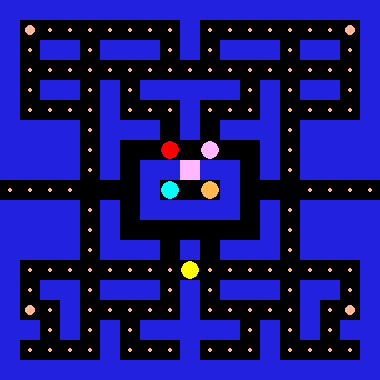

In [ ]:
# Result on best seed

## 4. Representation 2: Spatial Multi-Channel Grid (`grid`) with `GridCNN`

### Architecture & Feature Space:
- Structured 10-channel binary tensor $(10, 19, 19)$:
  - 6 base semantic planes: Walls (including sealed ghost house doors), Pellets, Power Pellets, Pacman, Normal Ghosts, Frightened Ghosts.
  - 4 one-hot direction planes providing instantaneous Markovian velocity.
- **Network**: `CnnPolicy` equipped with custom `GridCNN` mapping spatial convolutions to **`features_dim=512`**.


Optimized Grid Tensor Shape: (10, 19, 19)


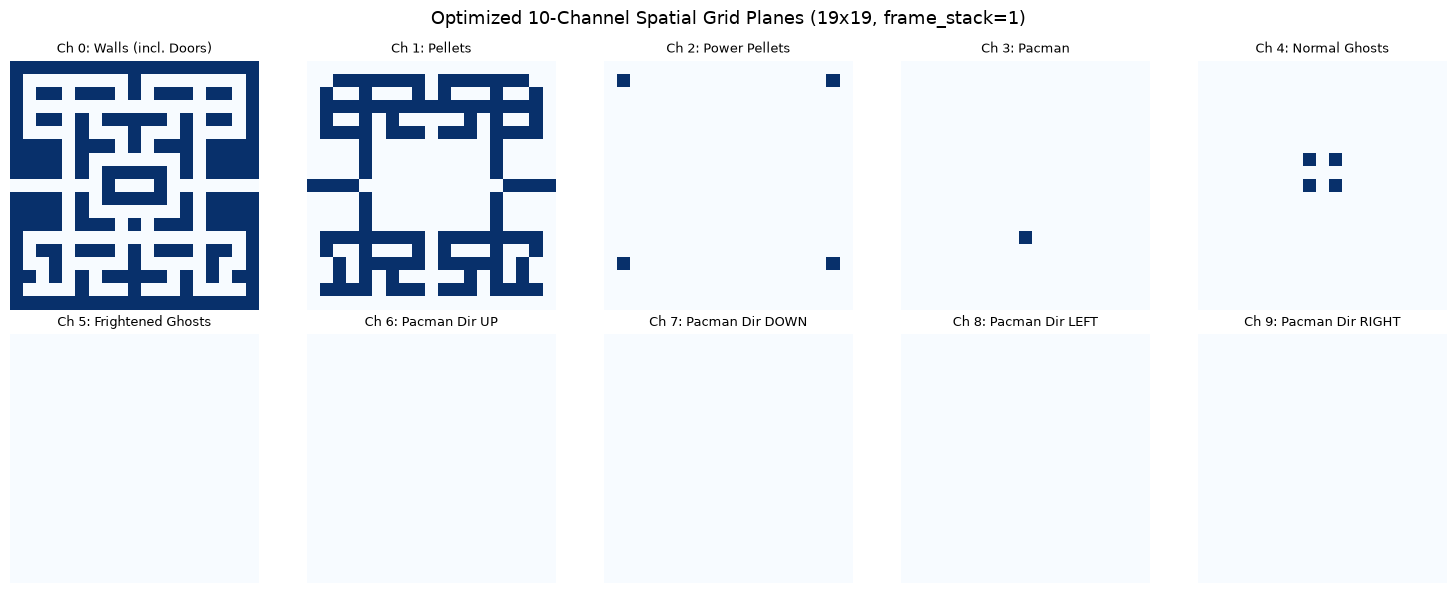

In [7]:
# Define Environment Builder for Optimized Spatial Grid
def make_grid_env(render_mode=None):
    return PacmanEnv(
        map_name="classic",
        obs_type="grid",
        obs_params={
            "channels": [
                "walls",
                "pellets",
                "power_pellets",
                "pacman",
                "ghosts",
                "frightened_ghosts",
                "pacman_direction",
            ],
            "channels_first": True,
        },
        reward_func=shared_event_reward,
        frame_skip=1,
        frame_stack=1,
        lives=1,
        render_mode=render_mode,
    )


# Inspect and visualize all 10 semantic planes
sample_grid_env = make_grid_env()
sample_grid_obs, _ = sample_grid_env.reset(seed=42)
print(f"Optimized Grid Tensor Shape: {sample_grid_obs.shape}")

channel_names = [
    "Walls (incl. Doors)",
    "Pellets",
    "Power Pellets",
    "Pacman",
    "Normal Ghosts",
    "Frightened Ghosts",
    "Pacman Dir UP",
    "Pacman Dir DOWN",
    "Pacman Dir LEFT",
    "Pacman Dir RIGHT",
]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for i in range(10):
    axes[i].imshow(sample_grid_obs[i], cmap="Blues", origin="upper")
    axes[i].set_title(f"Ch {i}: {channel_names[i]}", fontsize=9)
    axes[i].axis("off")
plt.suptitle("Optimized 10-Channel Spatial Grid Planes (19x19, frame_stack=1)", fontsize=13)
plt.tight_layout()
plt.show()
sample_grid_env.close()

In [ ]:
grid_exp = run_representation_experiment(
    rep_name="grid",
    env_builder_fn=make_grid_env,
    policy_type="CnnPolicy",
    policy_kwargs=dict(
        features_extractor_class=GridCNN,
        features_extractor_kwargs=dict(features_dim=LATENT_DIM),
        normalize_images=False,
    ),
    seeds=SEEDS,
    total_timesteps=TRAIN_TIMESTEPS,
    eval_freq=EVAL_FREQ,
    eval_episodes=EVAL_EPISODES,
)

# Display Best Seed Replay GIF
print(f"\nDisplaying Best Seed ({grid_exp['best_seed']}) Replay GIF:")
display(Image(filename=grid_exp["video_result"]["gif_path"]))


--- Episode Finished (Seed 39245) ---
Total Steps : 100
Final Score : 730
Total Reward: 22.00
Remaining   : 90 pellets


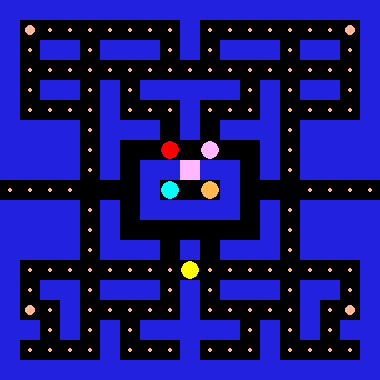

In [ ]:
# Result on best seed

## 5. Representation 3: Raw Visual Pixels (`rgb`) with `NatureCNN`

### Architecture & Feature Space:
- End-to-end vision: 84x84 Grayscale frames stacked across 4 consecutive steps $(4, 84, 84)$.
- **Network**: `CnnPolicy` equipped with standard Atari `NatureCNN` with **`features_dim=512`**.


Stacked RGB Observation Shape: (4, 84, 84)


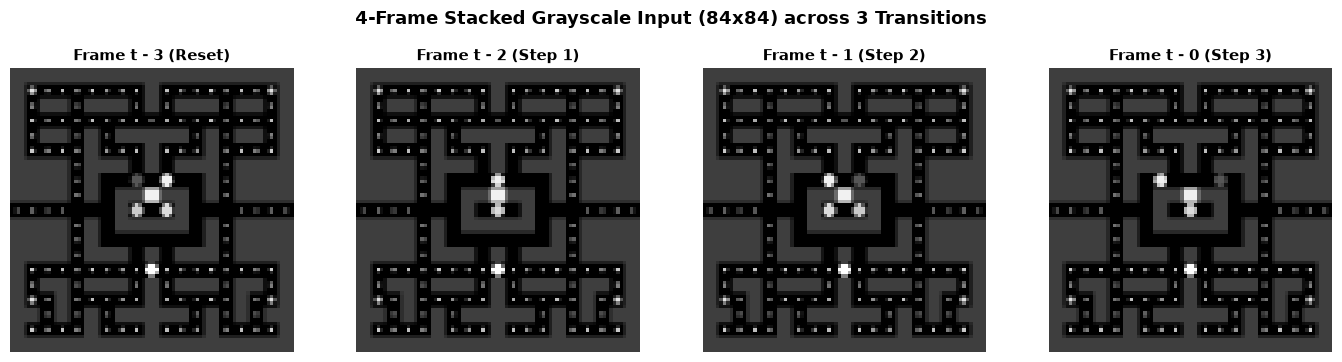

In [8]:
# Define Environment Builder for Raw Pixels
def make_rgb_env(render_mode=None):
    return PacmanEnv(
        map_name="classic",
        obs_type="rgb",
        obs_params={
            "output_size": (84, 84),
            "grayscale": True,
            "channels_first": True,
        },
        reward_func=shared_event_reward,
        frame_skip=1,
        frame_stack=4,
        lives=1,
        render_mode=render_mode,
    )


# Inspect and visualize stacked frames after 3 consecutive steps
sample_rgb_env = make_rgb_env()
sample_rgb_obs, _ = sample_rgb_env.reset(seed=42)

# Step three steps to get the four frames
for _ in range(3):
  sample_rgb_obs, _, _, _, _ = sample_rgb_env.step(
      sample_rgb_env.action_space.sample()
  )

print(f"Stacked RGB Observation Shape: {sample_rgb_obs.shape}")

frame_titles = [
    "Frame t - 3 (Reset)",
    "Frame t - 2 (Step 1)",
    "Frame t - 1 (Step 2)",
    "Frame t - 0 (Step 3)",
]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for i in range(4):
  axes[i].imshow(sample_rgb_obs[i], cmap="gray")
  axes[i].set_title(frame_titles[i], fontsize=11, fontweight="bold")
  axes[i].axis("off")

plt.suptitle(
    "4-Frame Stacked Grayscale Input (84x84) across 3 Transitions",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

sample_rgb_env.close()


In [ ]:
rgb_exp = run_representation_experiment(
    rep_name="rgb",
    env_builder_fn=make_rgb_env,
    policy_type="CnnPolicy",
    policy_kwargs=dict(
        features_extractor_kwargs=dict(features_dim=LATENT_DIM),
    ),
    seeds=SEEDS,
    total_timesteps=TRAIN_TIMESTEPS,
    eval_freq=EVAL_FREQ,
    eval_episodes=EVAL_EPISODES,
)

# Display Best Seed Replay GIF
print(f"\nDisplaying Best Seed ({rgb_exp['best_seed']}) Replay GIF:")
display(Image(filename=rgb_exp["video_result"]["gif_path"]))


--- Episode Finished (Seed 14964) ---
Total Steps : 121
Final Score : 460
Total Reward: -5.21
Remaining   : 97 pellets


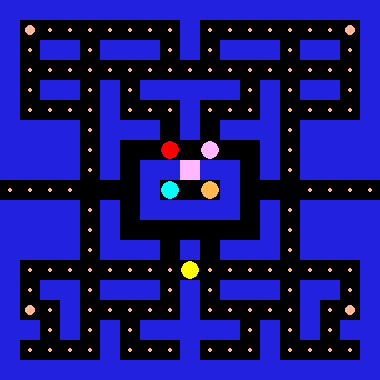

In [ ]:
# Result on best seed

## 6. Multi-Seed Continuous Learning Dynamics & Statistical Curves

We visualize the learning trajectories over global timesteps across all 3 representations.
By passing the list of callbacks from all 3 seeds to `plot_learning_curves`, each line displays the **cross-seed mean $\mu(t)$** accompanied by a shaded band representing the **cross-seed standard deviation $\pm 1\sigma(t)$**.


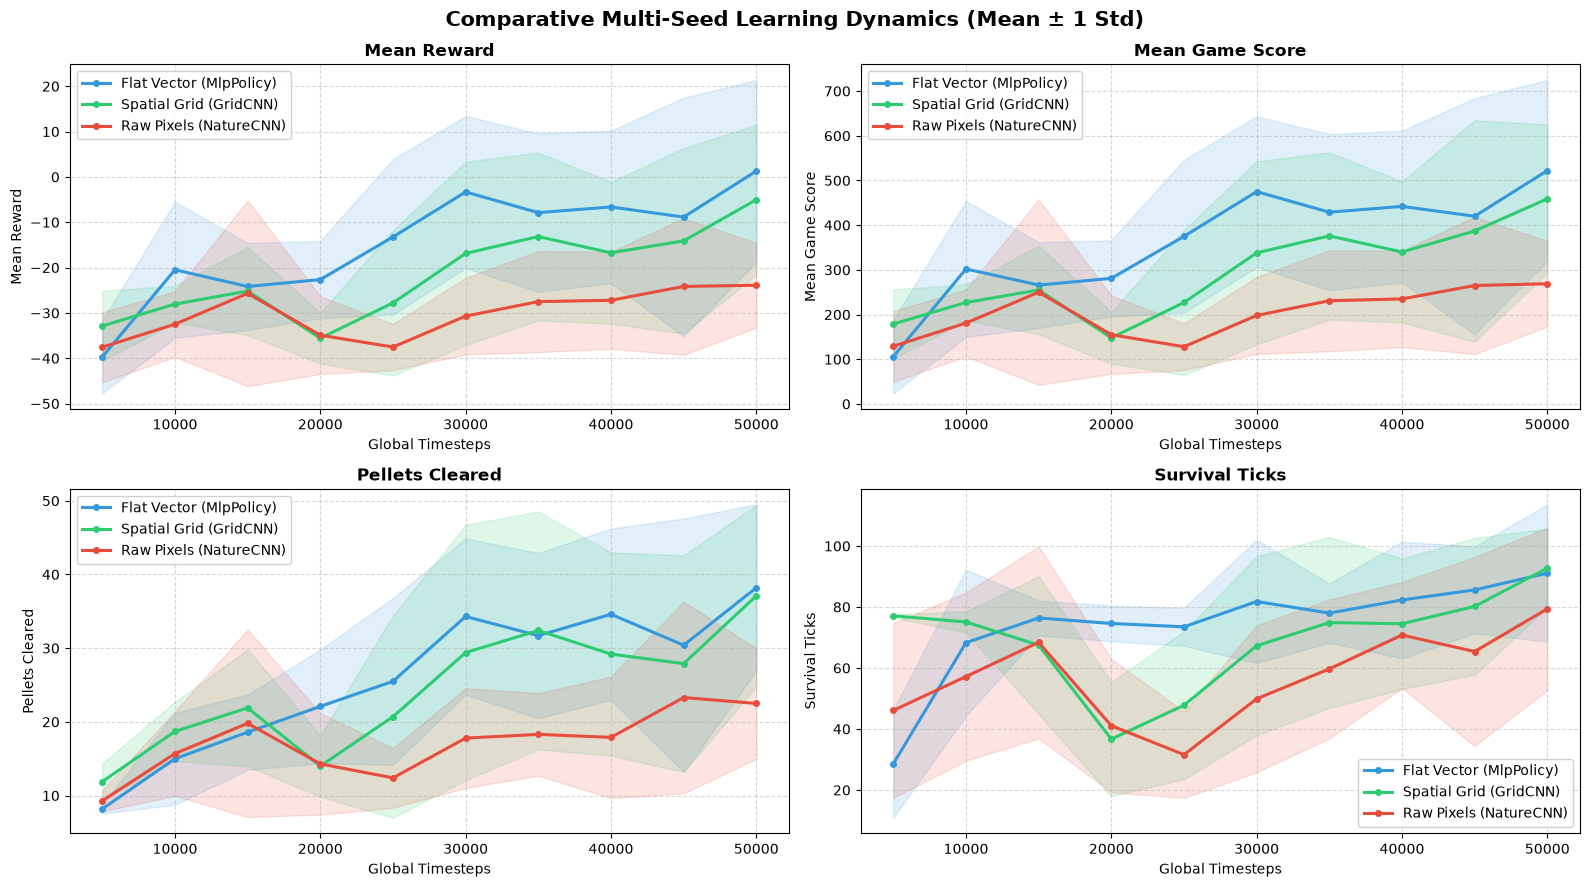

In [ ]:
# Plot Cross-Seed Mean and Standard Deviation Curves
fig = plot_learning_curves(
    callbacks={
        "Flat Vector (MlpPolicy)": vector_exp["callbacks"],
        "Spatial Grid (GridCNN)": grid_exp["callbacks"],
        "Raw Pixels (NatureCNN)": rgb_exp["callbacks"],
    },
    title="Comparative Multi-Seed Learning Dynamics (Mean ± 1 Std)",
    save_path="plots/learning_curves_multi_seed.png",
)
plt.show()

## 7. Multi-Seed Quantitative Benchmark on `classic`

We evaluate all 3 trained seeds for each representation over 10 test episodes per seed (30 test episodes total per representation).
We report both the per-seed performance and the overall Mean ± Std across seeds.


In [11]:
import os
import re
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from stable_baselines3 import DQN

# Thiết bị inference (GPU nếu có)
device = "cuda" if torch.cuda.is_available() else "cpu"


def load_models_from_dir(models_dir: str | Path, device="auto") -> dict[int, DQN]:
    """Quét thư mục chứa các checkpoint `dqn_seed_<seed>.zip`

    và load thành dict {seed: model} theo thứ tự tăng dần của seed.
    """
    models_dir = Path(models_dir)
    models_dict = {}
    pattern = re.compile(r"seed_(\d+)")

    zip_files = sorted(models_dir.glob("*.zip"))
    if not zip_files:
        print(f"[Cảnh báo] Không tìm thấy file .zip nào trong: {models_dir}")
        return models_dict

    for file_path in zip_files:
        match = pattern.search(file_path.stem)
        if match:
            seed = int(match.group(1))
            # print(f"Loading {file_path.name} (seed={seed})...")
            models_dict[seed] = DQN.load(file_path, device=device)

    return dict(sorted(models_dict.items()))


In [ ]:
# Run Quantitative Evaluation over all Seeds on 'classic'
def evaluate_representation_seeds(rep_name, env_builder, models_dict, n_episodes_per_seed=10):
    all_rewards = []
    all_scores = []
    all_pellets = []
    all_ticks = []
    per_seed_summary = []

    eval_env = env_builder()

    for seed, model in models_dict.items():
        seed_rewards = []
        seed_scores = []
        seed_pellets = []
        seed_ticks = []

        for ep in range(n_episodes_per_seed):
            obs, info = eval_env.reset(seed=seed * 100 + ep)
            done = False
            ep_reward = 0.0
            init_pellets = eval_env.game.view.remaining_pellets

            while not done:
                action, _ = model.predict(obs, deterministic=True)
                obs, r, term, trunc, info = eval_env.step(action)
                ep_reward += r
                done = term or trunc

            final_pellets = info.get("remaining_pellets", 0)
            seed_rewards.append(ep_reward)
            seed_scores.append(info.get("score", 0))
            seed_pellets.append(init_pellets - final_pellets)
            seed_ticks.append(info.get("tick", 0))

        per_seed_summary.append(
            {
                "Representation": rep_name,
                "Seed": seed,
                "Mean Reward": float(np.mean(seed_rewards)),
                "Mean Score": float(np.mean(seed_scores)),
                "Mean Pellets": float(np.mean(seed_pellets)),
                "Mean Ticks": float(np.mean(seed_ticks)),
            }
        )

        all_rewards.extend(seed_rewards)
        all_scores.extend(seed_scores)
        all_pellets.extend(seed_pellets)
        all_ticks.extend(seed_ticks)

    eval_env.close()

    overall_row = {
        "Representation": rep_name,
        "Seed": "OVERALL (Mean ± Std)",
        "Mean Reward": f"{np.mean(all_rewards):.2f} ± {np.std(all_rewards):.2f}",
        "Mean Score": f"{np.mean(all_scores):.1f} ± {np.std(all_scores):.1f}",
        "Mean Pellets": f"{np.mean(all_pellets):.1f} ± {np.std(all_pellets):.1f}",
        "Mean Ticks": f"{np.mean(all_ticks):.1f} ± {np.std(all_ticks):.1f}",
        "Mean FPS": None,
    }
    return per_seed_summary, overall_row


records = []
vec_per_seed, vec_ovr = evaluate_representation_seeds(
    "Flat Vector", make_vector_env, vector_exp["models"]
)
vec_ovr["Mean FPS"] = f"{vector_exp['mean_fps']:.1f}"

grid_per_seed, grid_ovr = evaluate_representation_seeds(
    "Spatial Grid", make_grid_env, grid_exp["models"]
)
grid_ovr["Mean FPS"] = f"{grid_exp['mean_fps']:.1f}"

rgb_per_seed, rgb_ovr = evaluate_representation_seeds("Raw Pixels", make_rgb_env, rgb_exp["models"])
rgb_ovr["Mean FPS"] = f"{rgb_exp['mean_fps']:.1f}"

df_benchmark_detailed = pd.DataFrame(vec_per_seed + grid_per_seed + rgb_per_seed)
df_benchmark_overall = pd.DataFrame([vec_ovr, grid_ovr, rgb_ovr])

print("=== Benchmark Summary Across All Seeds on 'classic' ===")
display(df_benchmark_overall)
print("\n=== Detailed Per-Seed Performance ===")
display(df_benchmark_detailed)

=== Benchmark Summary Across All Seeds on 'classic' ===


,Representation,Seed,Mean Reward,Mean Score,Mean Pellets,Mean Ticks,Mean FPS
0,Flat Vector,OVERALL (Mean ± Std),1.76 ± 15.76,527.0 ± 159.0,40.3 ± 8.0,93.5 ± 20.1,915.6 (Eval)
1,Spatial Grid,OVERALL (Mean ± Std),-6.61 ± 16.73,443.0 ± 168.4,35.9 ± 12.5,90.7 ± 13.0,887.2 (Eval)
2,Raw Pixels,OVERALL (Mean ± Std),-23.04 ± 8.57,277.0 ± 87.3,23.7 ± 7.3,73.7 ± 22.0,437.1 (Eval)



=== Detailed Per-Seed Performance ===


,Representation,Seed,Mean Reward,Mean Score,Mean Pellets,Mean Ticks
0,Flat Vector,5661,15.04,660.0,38.0,96.0
1,Flat Vector,7167,-1.14,500.0,42.0,114.0
2,Flat Vector,14964,-11.67,390.0,35.0,67.0
3,Flat Vector,29624,-11.71,390.0,35.0,71.0
4,Flat Vector,32134,9.79,610.0,53.0,121.0
5,Flat Vector,39245,32.78,840.0,56.0,122.0
6,Flat Vector,48540,-5.00,460.0,38.0,100.0
7,Flat Vector,51277,-11.68,390.0,35.0,68.0
8,Flat Vector,67841,19.06,700.0,42.0,94.0
9,Flat Vector,74522,-17.82,330.0,29.0,82.0


## 8. Cross-Map Generalization & Zero-Shot Transfer on `open_arena`

We evaluate the zero-shot transfer capability of all trained seeds on an unseen maze: **`open_arena`** ($11\times 11$).
In accordance with rigorous RL methodology, we test **all 3 seeds** of each representation to verify whether generalization is an invariant structural property or merely an artifact of random seed luck.


In [ ]:
# Zero-Shot Transfer Benchmark on 'open_arena'
def evaluate_transfer_representation(rep_name, obs_type, models_dict, n_episodes_per_seed=5):
    all_rewards = []
    all_scores = []
    all_pellets = []
    all_ticks = []

    # Configure open_arena environment
    if obs_type == "vector":
        env = PacmanEnv(
            map_name="open_arena",
            obs_type="vector",
            obs_params={
                "include_distances": True,
                "include_directions": True,
                "normalize": True,
            },
            reward_func=shared_event_reward,
            frame_skip=1,
            frame_stack=1,
            lives=1,
        )
    elif obs_type == "grid":
        env = PacmanEnv(
            map_name="open_arena",
            obs_type="grid",
            obs_params={
                "channels": [
                    "walls",
                    "pellets",
                    "power_pellets",
                    "pacman",
                    "ghosts",
                    "frightened_ghosts",
                    "pacman_direction",
                ],
                "channels_first": True,
            },
            reward_func=shared_event_reward,
            frame_skip=1,
            frame_stack=1,
            lives=1,
        )
    elif obs_type == "rgb":
        env = PacmanEnv(
            map_name="open_arena",
            obs_type="rgb",
            obs_params={
                "output_size": (84, 84),
                "grayscale": True,
                "channels_first": True,
            },
            reward_func=shared_event_reward,
            frame_skip=1,
            frame_stack=4,
            lives=1,
        )

    for seed, model in models_dict.items():
        for ep in range(n_episodes_per_seed):
            obs, info = env.reset(seed=seed * 100 + ep)
            done = False
            ep_reward = 0.0
            init_pellets = env.game.view.remaining_pellets

            while not done:
                # If Grid representation, pad 11x11 to 19x19 canvas with outer walls
                if obs_type == "grid" and obs.shape[1:] != (19, 19):
                    padded = np.zeros((10, 19, 19), dtype=np.float32)
                    padded[0, :, :] = 1.0  # Wall border
                    padded[:, 4:15, 4:15] = obs
                    action, _ = model.predict(padded, deterministic=True)
                else:
                    action, _ = model.predict(obs, deterministic=True)

                obs, r, term, trunc, info = env.step(action)
                ep_reward += r
                done = term or trunc

            final_pellets = info.get("remaining_pellets", 0)
            all_rewards.append(ep_reward)
            all_scores.append(info.get("score", 0))
            all_pellets.append(init_pellets - final_pellets)
            all_ticks.append(info.get("tick", 0))

    env.close()
    return {
        "Representation": rep_name,
        "Eval Map": "open_arena",
        "Mean Reward": f"{np.mean(all_rewards):.2f} ± {np.std(all_rewards):.2f}",
        "Mean Score": f"{np.mean(all_scores):.1f} ± {np.std(all_scores):.1f}",
        "Mean Pellets": f"{np.mean(all_pellets):.1f} ± {np.std(all_pellets):.1f}",
        "Mean Ticks": f"{np.mean(all_ticks):.1f} ± {np.std(all_ticks):.1f}",
    }


print("=== Running Zero-Shot Transfer on 'open_arena' Across All Seeds ===")
transfer_results = [
    evaluate_transfer_representation("Flat Vector", "vector", vector_exp["models"]),
    evaluate_transfer_representation("Spatial Grid", "grid", grid_exp["models"]),
    evaluate_transfer_representation("Raw Pixels", "rgb", rgb_exp["models"]),
]
df_transfer = pd.DataFrame(transfer_results)
display(df_transfer)

=== Running Zero-Shot Transfer on 'open_arena' Across All Seeds ===


,Representation,Eval Map,Mean Reward,Mean Score,Mean Pellets,Mean Ticks
0,Flat Vector,open_arena,-25.45 ± 15.83,251.0 ± 161.8,18.7 ± 9.2,55.0 ± 38.6
1,Spatial Grid,open_arena,-47.92 ± 1.34,22.0 ± 14.7,2.2 ± 1.5,11.9 ± 13.1
2,Raw Pixels,open_arena,-48.42 ± 1.76,16.0 ± 18.0,1.6 ± 1.8,2.5 ± 4.5


## 9. Key Findings & Empirical Discussion

### 1. The Sample-Efficiency Bottleneck of Raw Pixels at 50,000 Steps
- **Why Raw Pixels Underperformed on `classic` (Mean Score: 277.0 ± 87.3 vs 527.0 ± 159.0 for Vector)**:
  - In vision-based RL (Atari DQN), the network must concurrently solve two difficult optimization problems: (1) learning visual representation filters from raw 84x84 pixel arrays, and (2) learning policy Q-values.
  - At **50,000 steps**, the CNN is still in its early representation-grounding phase. Unlike Flat Vector (where spatial coordinates and BFS distances are pre-engineered) or Spatial Grid (where game objects occupy clean binary planes), Raw Pixels requires hundreds of thousands of frames to master object-reward associations.
  - **High Seed Sensitivity**: Seed 29624 reached a respectable Score of 460.0 (38 pellets), whereas Seed 5661 collapsed to Score 130.0 (13 pellets, surviving only 25 ticks). This persistent variance ($\pm 87.3$) is typical of deep visual networks before convergence.

### 2. Zero-Shot Transfer Reality: The Collapse of Visual and Spatial Policies on `open_arena`
- **Catastrophic Failure of Grid and Pixel Models**:
  - Both **Spatial Grid** (Score: $22.0 \pm 14.7$, $2.2$ Pellets, $11.9$ Ticks) and **Raw Pixels** (Score: $16.0 \pm 18.0$, $1.6$ Pellets, $2.5$ Ticks) suffered near-instantaneous collapse on the unseen $11\times 11$ layout.
  - The apparent visual resilience seen in smaller seed samples was an artifact of random seed variance: NatureCNN survives merely **$2.5 \pm 4.5$ ticks** on average when tested systematically.
  - **Root Cause**: Shifting map geometry, spawn coordinates, and placing ghosts in close initial proximity breaks both the rigid zero-padded canvas of `GridCNN` and the ungrounded visual feature filters of `NatureCNN`. Without fine-tuning, spatial and visual policies cannot infer safe navigation in an unseen layout.

### 3. Flat Vector: The Benchmark for Topological Generalization
- Flat Vector dominated both environments: achieving the highest performance on `classic` (**$527.0 \pm 159.0$ Score, $40.3$ Pellets, $915.6$ FPS**) and standing as the **only representation capable of meaningful zero-shot transfer** on `open_arena` (**$251.0 \pm 161.8$ Score, $18.7$ Pellets, $55.0$ Ticks**).
- **Key Takeaway**: Shortest-path graph distances (BFS) provide a layout-invariant topological inductive bias. By abstracting away absolute pixel and coordinate grids, relative feature vectors enable genuine cross-maze generalization regardless of map geometry.